In [8]:
import sys
import os
import numpy as np
import scipy as sp
import pandas as pd
from matplotlib import pyplot as plt

from sklearn.cross_decomposition import CCA


sys.path.append(os.path.join(os.getcwd(), '../'))
from utils_fly import read_utils

sys.path.append(os.path.join(os.getcwd(), '../../../../'))
from utils import plot_utils
from utils import train_utils

In [9]:
import importlib
importlib.reload(read_utils)
importlib.reload(plot_utils)
importlib.reload(train_utils)

<module 'utils.train_utils' from '/home/julian-zim/Files/Cloud/OneDrive/OneFiles/Linux/ZimmerLab/MSc_Thesis/Workspace/hobe/organisms/fly-2023-schaffer/src/manifold/../../../../utils/train_utils.py'>

In [10]:
dims = 3
dims_preca = 5

read_ids = list(range(0, 12+1))
# read_ids = [0,   # paper
# 			2,
# 			3,
# 			4,
# 			5,
# 			6,
# 			8,
# 			9]   # good
# read_ids = [0]
plot_id = 0

In [11]:
# read

path = os.path.join(read_utils.get_data_path(), 'brain')
(file_ids, filenames,
 traces,
 states, markers) = read_utils.get_data(path, read_ids)

# # clear nan values
# for i in range(len(file_ids)):
# 	mask = markers[i].notna().all(axis=1)
#
# 	traces[i] = traces[i][mask]
# 	markers[i] = markers[i][mask]
# 	states[i] = states[i][mask]
#
# 	#filenames[i] = filenames[i][mask]

# naive ID unknown neurons
for i in range(len(file_ids)):
	traces[i].columns = pd.Index([
		f'{file_ids[i]:02d}_{n_id:03d}' if empty else label for n_id, (label, empty) in enumerate(zip(traces[i].columns, traces[i].columns == ''))
	])

In [12]:
# prep

def highpass_butter(x, fs, cutoff_hz, order=4, axis=0):
    return sp.signal.sosfiltfilt(sp.signal.butter(order, cutoff_hz, btype='highpass', fs=fs, output='sos'), x, axis=axis)

sampling_rates = [read_utils.get_sampling_rate(os.path.join(path, filenames[file_ids.index(file_id)])) for file_id in file_ids]

traces = [pd.DataFrame(highpass_butter(trace.values, sr, 1 / 100), columns=trace.columns) for trace, sr in zip(traces, sampling_rates)]

markers_grad = [pd.DataFrame(np.gradient(marker.values, axis=0), columns=marker.columns) for marker in markers]

In [13]:
selection_bhl = ['walk', 'still', 'front-groom', 'back-groom', 'abdomen-move', 'background']

plot_idx = file_ids.index(plot_id)

# discrete_states = [ds[selection_bhl] for ds in discrete_states]

In [14]:
(modes_manifold, modes_manifold_b,
 recos_manifold, recos_manifold_b,
 loads_cca_man, loads_cca_man_b,
 vars_expl_mans, vars_expl_mans_rs) = train_utils.get_manifolds_cca(traces,
																	[s[selection_bhl] for s in states],
																	zscore=(False, False),
																	n_cv=dims, n_pc=dims_preca)

In [15]:
save = False

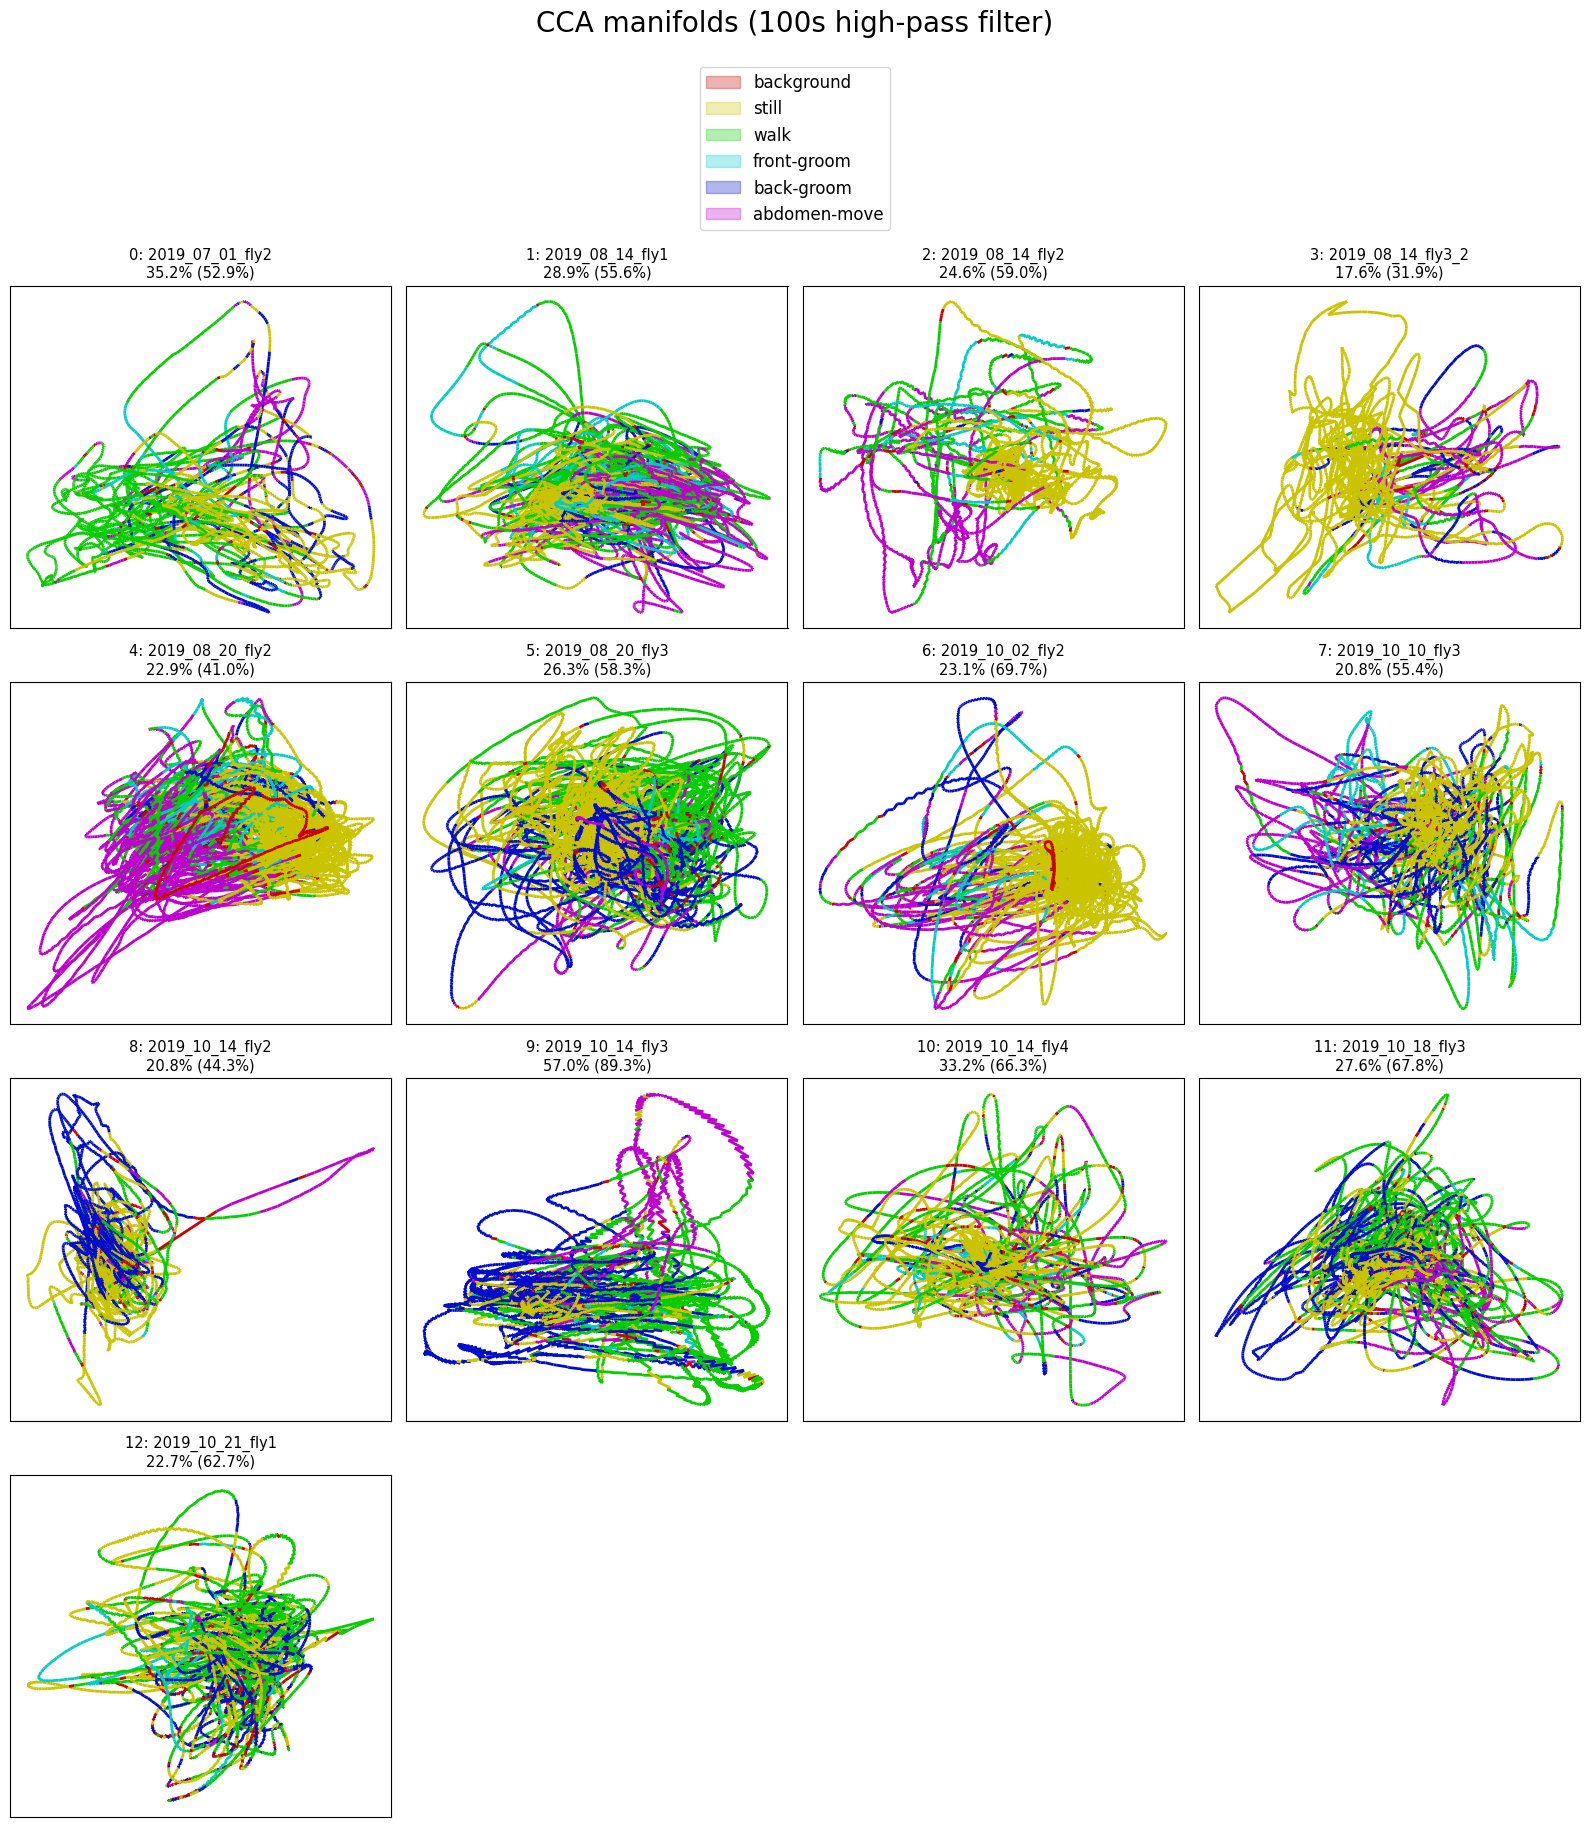

27.8% (29.0%)


In [16]:
plot_utils.plot_manifolds([f'{str(file_id)}: {filenames[file_ids.index(file_id)]}' for file_id in file_ids],
						  modes_manifold, states,
						  [vx[:2] for vx in vars_expl_mans], [vx[:2] for vx in vars_expl_mans_rs] if dims_preca > 0 else None,
						  title='CCA manifolds (100s high-pass filter)', top_space=2.5,
						  save_path=f'../../out/plots/manifolds/{dims}-dim-CCA' if save else None)

In [17]:
# plot_utils.plot_manifolds_3d([f'{str(file_id)}: {filenames[file_ids.index(file_id)]}' for file_id in file_ids],
# 							 modes_manifold, states,
# 							 [vx[:3] for vx in vars_expl_mans], [vx[:3] for vx in vars_expl_mans_rs] if dims_preca > 0 else None,
# 							 title='CCA manifolds (100s high-pass filter)', top_space=3,
# 							 save_path=f'../../out/plots/manifolds/{dims}-dim-CCA_3d' if save else None)

In [18]:
for file_id in file_ids:
	corrs = [
		np.corrcoef(modes_manifold[file_ids.index(file_id)].values[:, i], modes_manifold_b[file_ids.index(file_id)].values[:, i])[0, 1] for i in range(modes_manifold[file_ids.index(file_id)].values.shape[1])
	]
	print(f'{file_id}: {filenames[file_ids.index(file_id)]}')
	for i, corr in enumerate(corrs):
		print(f'\tCV{i}: {corr:.2f}')

0: 2019_07_01_fly2
	CV0: 0.64
	CV1: 0.39
	CV2: 0.18
1: 2019_08_14_fly1
	CV0: 0.47
	CV1: 0.29
	CV2: 0.18
2: 2019_08_14_fly2
	CV0: 0.61
	CV1: 0.43
	CV2: 0.15
3: 2019_08_14_fly3_2
	CV0: 0.63
	CV1: 0.22
	CV2: 0.11
4: 2019_08_20_fly2
	CV0: 0.77
	CV1: 0.36
	CV2: 0.10
5: 2019_08_20_fly3
	CV0: 0.47
	CV1: 0.33
	CV2: 0.06
6: 2019_10_02_fly2
	CV0: 0.72
	CV1: 0.28
	CV2: 0.08
7: 2019_10_10_fly3
	CV0: 0.53
	CV1: 0.32
	CV2: 0.28
8: 2019_10_14_fly2
	CV0: 0.48
	CV1: 0.41
	CV2: 0.19
9: 2019_10_14_fly3
	CV0: 0.65
	CV1: 0.48
	CV2: 0.17
10: 2019_10_14_fly4
	CV0: 0.36
	CV1: 0.19
	CV2: 0.13
11: 2019_10_18_fly3
	CV0: 0.45
	CV1: 0.27
	CV2: 0.12
12: 2019_10_21_fly1
	CV0: 0.36
	CV1: 0.20
	CV2: 0.16


In [19]:
# traces_manifolds_indices = [np.argsort(xloads_cca_man[0, :]) for xloads_cca_man in loads_cca_man]
#
# traces_sorted = [t.iloc[:, t_man_idx.tolist()] for t, t_man_idx in zip(traces, traces_manifolds_indices)]
#
# traces_manifolds_sorted = [t_man.iloc[:, t_man_idx.tolist()] for t_man, t_man_idx in zip(recos_manifold, traces_manifolds_indices)]
#
# traces_residuals = [pd.DataFrame(data=t.values - t_man.values, columns=t.columns) for t, t_man in zip(traces, recos_manifold)]
#
# traces_residuals_sorted_by_manifold = [t_res.iloc[:, t_man_idx.tolist()] for t_res, t_man_idx in zip(traces_residuals, traces_manifolds_indices)]